In [1]:
import jax
jax.config.update('jax_platform_name', 'cpu')
import os 
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import sys 
sys.path.insert(1, '../')

import plotly.graph_objs as go
from plotly.offline import iplot

from jax import numpy as jnp
import numpy as np

from scipy.ndimage import gaussian_filter

import matplotlib.pyplot as plt

from tqdm.notebook import tqdm

from functools import partial

In [10]:
pm_seed = 4
# num_its = 25
i_list = range(100)
# i_list = range(100)
# i_list = range(1)
# i_list = list(range(0, 0+num_its)) + list(range(25, 25+num_its)) + list(range(50, 50+num_its)) + list(range(75, 75+num_its))
save_dirs = ['../../exp/vol_jwst%d_L_2_Lz_5_proj_gg_shape_sigma_0.25_lam_0.03/%d'%(pm_seed, i) for i in i_list]

# wiener_recon = jnp.load('../../wiener_recon/pm%d_wiener.npy'%pm_seed).transpose((1,2,0))
wiener_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/wiener_jwst_4.npy').transpose(1, 2, 0)
print(wiener_recon.shape)
ddpm_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4.npy')[:, 20:89, -69:] .transpose(1, 2, 0)
ddpm_samples = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_samples.npy')[:, :, 20:89, -69:].transpose(0, 2, 3, 1)
density_paths = [save_dir + '/density/density_500.p' for save_dir in save_dirs]
# density_paths_2 = [save_dir + '/density/density_500.p' for save_dir in save_dirs_2]

daps_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_nops.npy')[:, 20:89, -69:] .transpose(1, 2, 0)

res = 69

(69, 69, 20)


In [11]:
def mean_subtract(vol, axis=(0,1)): 
    return vol - jnp.mean(vol, axis=axis, keepdims=True)
densities = [mean_subtract(jnp.load(density_path).reshape(res, res, 20)) for density_path in density_paths]
densities_arr = jnp.array(densities)

In [12]:
print(densities_arr.shape, ddpm_samples.shape)

(100, 69, 69, 20) (64, 69, 69, 20)


In [15]:
def mean_diffs(samples):
    diff_list = []
    for i in range(len(samples)):
        if i == 0: 
            mean_last = samples[0]
            continue
        mean_current = jnp.mean(samples[:i+1], axis=0)
        diff = jnp.linalg.norm(mean_current - mean_last)
        diff_list.append(diff)
        mean_last = mean_current 
    return diff_list 

diff_list_ddpm = mean_diffs(ddpm_samples)
diff_list_neur = mean_diffs(densities_arr)

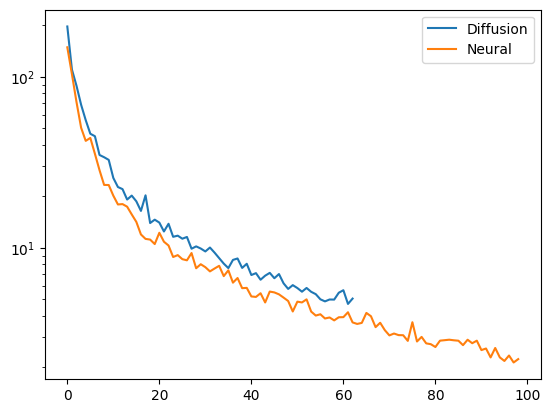

In [16]:
plt.semilogy(diff_list_ddpm, label='Diffusion')
plt.semilogy(diff_list_neur, label='Neural')
plt.legend()
plt.show()